In [1]:
"""
mPING verification sample: observed-class assignment and report distribution.

Observed class = modal (most-reported) precipitation type in each mPING record
(site x hour), with ties broken by the training-data hierarchy
    freezing rain > ice pellets > snow > rain.
No agreement threshold is applied. This is the same rule as OBS_RULE = "modal"
in notebooks 01-04, so the counts here match the verification sample.

Figure
  (a) Records per observed class; hatched caps = records whose class was set
      by the tie-break hierarchy.
  (b) Reporter agreement within the records of each class (100 % stacked):
      single-report records, unanimous multi-report records, and decreasing
      levels of agreement down to ties. Shows how clear-cut each class's
      labels are.
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch

Valid times: 475
Records: 30,856 (39,142 reports)
Single-report records: 25,650 (83.1%)
Tie-resolved records: 840 (2.72%)

By observed class:
               Records  Percent  Reports  Tie-resolved
obs_class                                             
Snow             16116    52.23    20246           136
Rain             11932    38.67    14590             0
Ice Pellet        1772     5.74     2786           504
Freezing Rain     1036     3.36     1520           200

Reporter agreement within each class (% of the class's records):
agreement      Single report  Unanimous (≥2 reports)  70–<100 % agree  50–<70 % agree  <50 % agree  Tie (hierarchy)
obs_class                                                                                                          
Snow                    84.5                    13.8              0.3             0.5          0.0              0.8
Rain                    86.2                    13.3              0.2             0.3          0.0              0.

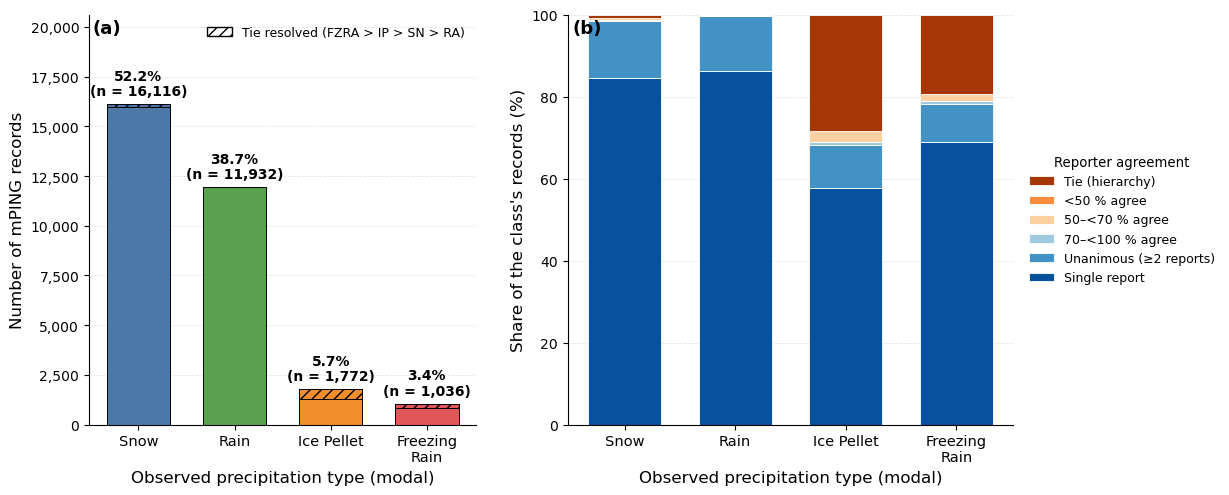

In [2]:


# ---------------------------------------------------------------------------
# Configuration 
# ---------------------------------------------------------------------------
MPING_PATH = ("/glade/campaign/cisl/aiml/ai2es/winter_ptypes/ptype_qc/"
              "mPING_hourafter_interpolated_QC3.parquet")

START = "2021-12-01"            # inclusive
END = "2022-04-01"              # exclusive -> last valid time 2022-03-31 18Z

#SYNOPTIC_HOURS = tuple(range(24))  # This is the full temporal range of the mping dataset
SYNOPTIC_HOURS =(0, 6, 12, 18) # select only the time values that match AI-NWP forecasts
LAT_MIN, LAT_MAX = 24.0, 50.0   # CONUS box
LON_MIN, LON_MAX = -125.0, -66.0

PTYPE_COLS = {                  # column -> label; order = plotting order
    "sn_percent": "Snow",
    "ra_percent": "Rain",
    "pl_percent": "Ice Pellet",
    "fzra_percent": "Freezing Rain",
}
CLASS_ORDER = list(PTYPE_COLS.values())

# Tie-break hierarchy (training-data rule): FZRA > IP > Snow > Rain
TIE_PRIORITY = ["fzra_percent", "pl_percent", "sn_percent", "ra_percent"]

PTYPE_COLORS = {
    "Snow": "#4C78A8",
    "Rain": "#59A14F",
    "Ice Pellet": "#F28E2B",
    "Freezing Rain": "#E15759",
}

# Agreement categories for panel (b): (label, colour)
AGREEMENT_CATS = [
    ("Single report",            "#08519C"),
    ("Unanimous (≥2 reports)",   "#4292C6"),
    ("70–<100 % agree",          "#9ECAE1"),
    ("50–<70 % agree",           "#FDD0A2"),
    ("<50 % agree",              "#FD8D3C"),
    ("Tie (hierarchy)",          "#A63603"),
]


# ---------------------------------------------------------------------------
# Data preparation
# ---------------------------------------------------------------------------
def load_mping(path=MPING_PATH, start=START, end=END, hours=SYNOPTIC_HOURS):
    """Load mPING records for the verification period, valid hours and CONUS.

    Class percentages are returned on a 0-100 scale. Pass hours=None to keep
    all 24 hours.
    """
    cols = ["datetime", "lat", "lon", "report_count", *PTYPE_COLS]
    df = pd.read_parquet(path, columns=cols)
    df["datetime"] = pd.to_datetime(df["datetime"])

    mask = (df["datetime"] >= start) & (df["datetime"] < end)
    if hours is not None:
        mask &= df["datetime"].dt.hour.isin(hours)
    mask &= df["lat"].between(LAT_MIN, LAT_MAX) & df["lon"].between(LON_MIN, LON_MAX)
    df = df.loc[mask].copy()

    pct = list(PTYPE_COLS)
    df[pct] = df[pct].fillna(0.0)
    if df[pct].to_numpy().max() <= 1.0:      # stored as fractions
        df[pct] *= 100.0

    bad = ~np.isclose(df[pct].sum(axis=1), 100.0, atol=0.5)
    if bad.any():
        print(f"Warning: {bad.sum():,} records with class percentages "
              "not summing to 100%.")
    return df.reset_index(drop=True)


def assign_modal_class(df):
    """Add obs_class (modal ptype), obs_consensus (0-100), obs_tie_resolved
    and agreement (category for panel b).

    idxmax returns the FIRST column at the maximum, so ordering the columns by
    TIE_PRIORITY breaks ties as FZRA > IP > Snow > Rain. Records with no
    reported ptype are dropped. Identical to assign_obs_class(OBS_RULE="modal")
    in notebooks 01 and 04.
    """
    raw = df[TIE_PRIORITY].astype(float)
    pct = raw.round(6)                       # guard float noise (2/3 etc.)
    vmax = pct.max(axis=1)

    out = df.copy()
    out["obs_consensus"] = raw.max(axis=1)
    out["obs_tie_resolved"] = pct.eq(vmax, axis=0).sum(axis=1) > 1
    out["obs_class"] = pct.idxmax(axis=1).map(PTYPE_COLS)
    out = out.loc[vmax > 0].copy()

    c = out["obs_consensus"].round(6)
    out["agreement"] = np.select(
        [out["obs_tie_resolved"],
         out["report_count"] <= 1,
         c >= 100,
         c >= 70,
         c >= 50],
        ["Tie (hierarchy)", "Single report", "Unanimous (≥2 reports)",
         "70–<100 % agree", "50–<70 % agree"],
        default="<50 % agree")
    return out.reset_index(drop=True)


# ---------------------------------------------------------------------------
# Summaries
# ---------------------------------------------------------------------------
def class_distribution(df):
    """Records, percent of records, reports, and tie-resolved records per class."""
    counts = df["obs_class"].value_counts().reindex(CLASS_ORDER, fill_value=0)
    reports = (df.groupby("obs_class")["report_count"].sum()
                 .reindex(CLASS_ORDER, fill_value=0))
    ties = (df.loc[df["obs_tie_resolved"], "obs_class"].value_counts()
              .reindex(CLASS_ORDER, fill_value=0))
    return pd.DataFrame({
        "Records": counts,
        "Percent": 100.0 * counts / counts.sum(),
        "Reports": reports,
        "Tie-resolved": ties,
    })


def agreement_table(df, normalize=True):
    """Agreement category by observed class (percent of the class's records)."""
    labels = [a for a, _ in AGREEMENT_CATS]
    tbl = (pd.crosstab(df["obs_class"], df["agreement"])
             .reindex(index=CLASS_ORDER, columns=labels, fill_value=0))
    if normalize:
        tbl = 100.0 * tbl.div(tbl.sum(axis=1).replace(0, np.nan), axis=0)
    return tbl


def tie_resolution_summary(df):
    """Which classes tied, and which class the hierarchy assigned."""
    tied = df[df["obs_tie_resolved"]]
    if tied.empty:
        print("No tied records.")
        return pd.DataFrame()
    pct = tied[list(PTYPE_COLS)].round(6)
    at_max = pct.eq(pct.max(axis=1), axis=0)
    combo = at_max.apply(lambda r: " + ".join(PTYPE_COLS[c] for c in r.index[r]), axis=1)
    tbl = (pd.DataFrame({"Tied classes": combo,
                         "Assigned class": tied["obs_class"],
                         "report_count": tied["report_count"]})
             .groupby(["Tied classes", "Assigned class"])
             .agg(Records=("report_count", "size"), Reports=("report_count", "sum"))
             .sort_values("Records", ascending=False))
    print(tbl.to_string())
    return tbl


def print_sample_summary(df):
    """Numbers for the Methods text and figure caption."""
    print(f"Valid times: {df['datetime'].nunique():,}")
    print(f"Records: {len(df):,} ({int(df['report_count'].sum()):,} reports)")
    print(f"Single-report records: {(df['report_count'] <= 1).sum():,} "
          f"({100 * (df['report_count'] <= 1).mean():.1f}%)")
    print(f"Tie-resolved records: {df['obs_tie_resolved'].sum():,} "
          f"({100 * df['obs_tie_resolved'].mean():.2f}%)")
    print("\nBy observed class:")
    print(class_distribution(df).round(2).to_string())
    print("\nReporter agreement within each class (% of the class's records):")
    print(agreement_table(df).round(1).to_string())
    print("\nTie resolution:")
    tie_resolution_summary(df)


def case_counts(df, valid_time):
    """Record/report counts at one valid time, by observed class."""
    sub = df[df["datetime"] == pd.Timestamp(valid_time)]
    return {"records": len(sub), "reports": int(sub["report_count"].sum()),
            "by_class": sub["obs_class"].value_counts().reindex(CLASS_ORDER, fill_value=0).to_dict(),
            "tie_resolved": int(sub["obs_tie_resolved"].sum())}


def check_against_verification(df, common_file):
    """Confirm this sample matches notebook 01's verification sample."""
    common = pd.read_parquet(common_file, columns=["obs_id", "datetime", "lat", "lon", "obs_class"])
    ref = common.drop_duplicates("obs_id")
    print(f"QC records: {len(df):,} | verification observations (notebook 01): {len(ref):,}")
    a = df["obs_class"].value_counts().reindex(CLASS_ORDER, fill_value=0)
    b = ref["obs_class"].value_counts().reindex(CLASS_ORDER, fill_value=0)
    print(pd.DataFrame({"QC script": a, "Notebook 01 (common sample)": b}).to_string())
    print("Note: the common sample can be slightly smaller (records dropped where any "
          "system had no valid prediction).")


# ---------------------------------------------------------------------------
# Figure
# ---------------------------------------------------------------------------
def _tick(label):
    return label.replace(" ", "\n") if label == "Freezing Rain" else label


def _style_axis(ax):
    ax.grid(axis="y", linestyle="--", linewidth=0.6, alpha=0.3)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.tick_params(axis="x", labelsize=10.5)
    ax.tick_params(axis="y", labelsize=10)


def plot_report_distribution(df, figsize=(12, 5.0), savepath=None):
    """(a) records per observed class with tie-resolved caps;
    (b) reporter agreement within each class (100 % stacked)."""
    dist = class_distribution(df)
    agree = agreement_table(df)
    ticks = [_tick(c) for c in CLASS_ORDER]

    fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=figsize,
                                     gridspec_kw={"wspace": 0.22, "width_ratios": [1, 1.15]})

    # ---- (a) records per class ---------------------------------------------
    ymax = dist["Records"].max()
    bars = ax_a.bar(ticks, dist["Records"], width=0.66,
                    color=[PTYPE_COLORS[c] for c in CLASS_ORDER],
                    edgecolor="black", linewidth=0.7)
    ax_a.bar(ticks, dist["Tie-resolved"], bottom=dist["Records"] - dist["Tie-resolved"],
             width=0.66, facecolor="none", edgecolor="black", hatch="///", linewidth=0.7)
    for bar, n, p in zip(bars, dist["Records"], dist["Percent"]):
        ax_a.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02 * ymax,
                  f"{p:.1f}%\n(n = {n:,})", ha="center", va="bottom",
                  fontsize=10, fontweight="bold", linespacing=1.1)
    ax_a.set_ylim(0, 1.28 * ymax)
    ax_a.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax_a.set_ylabel("Number of mPING records", fontsize=12)
    ax_a.set_xlabel("Observed precipitation type (modal)", fontsize=12)
    ax_a.legend(handles=[Patch(facecolor="white", edgecolor="black", hatch="///",
                               label="Tie resolved (FZRA > IP > SN > RA)")],
                loc="upper right", frameon=False, fontsize=9)

    # ---- (b) agreement within class ----------------------------------------
    bottom = np.zeros(len(CLASS_ORDER))
    for label, color in AGREEMENT_CATS:
        v = agree[label].fillna(0).to_numpy()
        ax_b.bar(ticks, v, bottom=bottom, width=0.66, color=color,
                 edgecolor="white", linewidth=0.6, label=label)
        bottom += v
    ax_b.set_ylim(0, 100)
    ax_b.set_ylabel("Share of the class's records (%)", fontsize=12)
    ax_b.set_xlabel("Observed precipitation type (modal)", fontsize=12)
    h, l = ax_b.get_legend_handles_labels()          # topxf of stack first
    ax_b.legend(h[::-1], l[::-1], loc="center left", bbox_to_anchor=(1.01, 0.5),
                frameon=False, fontsize=9, title="Reporter agreement", title_fontsize=9.5)

    for ax, tag in ((ax_a, "(a)"), (ax_b, "(b)")):
        _style_axis(ax)
        ax.text(0.01, 0.99, tag, transform=ax.transAxes, ha="left", va="top",
                fontsize=13, fontweight="bold")

    fig.subplots_adjust(left=0.07, right=0.84, bottom=0.15, top=0.97)
    if savepath:
        fig.savefig(f"{savepath}.pdf", bbox_inches="tight")
        # fig.savefig(f"{savepath}.png", dpi=300, bbox_inches="tight")
    return fig, (ax_a, ax_b)


if __name__ == "__main__":
    obs = assign_modal_class(load_mping())
    print_sample_summary(obs)
    print(case_counts(obs, "2022-02-03 18:00"))
    # Optional consistency check against notebook 01 (modal-rule output folder):
    # check_against_verification(obs, "/glade/derecho/scratch/sakor/bulk/era5_init/ML_PTYPE/"
    #     "verification_multimodel_modal/common_valid_multimodel_predictions.parquet")
    plot_report_distribution(obs, savepath="../figures_modal/fig_mping_report_distribution")
    plt.show()